# Black-Scholes PINN Implementation

In this notebook, I implemented a Physics-Informed Neural Network (PINN) to approximate the solution of the Black-Scholes PDE for a European call option.

The aim is to train a neural network to learn the option price $V(S, \tau)$, where:

- $S$ is the stock price
- $\tau$ is the time to maturity
- $V(S, \tau)$ is the option value

I used $\tau = T - t$, so the Black-Scholes PDE is written in forward time-to-maturity form:

$$\frac{\partial V}{\partial \tau}=\frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2}+ rS \frac{\partial V}{\partial S}- rV$$

The PINN is trained by minimizing a loss function made up of four parts:

1. PDE loss: measures how well the neural network satisfies the Black-Scholes PDE inside the domain.
2. Lower boundary loss: enforces the option price at the lower stock price boundary.
3. Upper boundary loss: enforces the option price at the upper stock price boundary.
4. Terminal payoff loss: enforces the European call payoff at $\tau = 0$.

For a European call option, the terminal payoff is:

$V(S,0) = \max(S-K,0)$

The boundary conditions used are:

$$V(0,t) = 0, V(S \to \infty,t) = S - Ke^{-r\tau}$$

The model uses the input pair $(S, \tau)$ and outputs an approximation to the option price $V(S, \tau)$.

The fixed parameter set used in this notebook is:

- Strike price: $K = 100$
- Maturity: $T = 1$
- Risk-free rate: $r = 0.05$
- Volatility: $\sigma = 0.2$
- $S_{max} = 3 \cdot K$

Once the PINN is trained, I compared its predicted option prices against the analytical Black-Scholes solution.

In [37]:
import sys
sys.path.append("..")

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import gc
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import norm
from src.metrics import error_summary
from src.metrics import mse, rmse, mae, max_abs_error, relative_l2_error
import pandas as pd

torch.set_num_threads(1)

from src.analytical import black_scholes_call_grid, call_price
from src.pinn import BlackScholesPINN
from src.training_points import generate_training_points
from src.losses import black_scholes_pde_loss
from src.evaluation import evaluate_model_on_grid, compute_metric_row

torch.manual_seed(42)
np.random.seed(42)


In [38]:
# Defining parameters.

K = 100  # Strike price
T = 1.0  # Time to maturity
r = 0.05  # Risk-free interest rate
sigma = 0.2  # Volatility
S_max = 3*K # Maximum stock price considered

In [51]:
# Training the PINN model.

model = BlackScholesPINN(
    layers=[2, 32, 32, 32, 1],
    S_max=S_max,
    T=T,
    price_scale=K
)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

loss_history = []

epochs = 5000

N_f = 500
N_ic = 200
N_bc = 200

def train_step():
    training_data = generate_training_points(N_f=N_f,N_ic=N_ic,N_bc=N_bc,S_max=S_max,T=T,K=K,r=r)

    optimizer.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = black_scholes_pde_loss(model,training_data,r=r,sigma=sigma,K=K)

    total_loss.backward()
    optimizer.step()

    values = (total_loss.detach().item(),loss_pde.detach().item(),loss_ic.detach().item(),loss_lb.detach().item(),loss_ub.detach().item())

    return values


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step()

    loss_history.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}")

Epoch 0: Total=6.080649e+00, PDE=8.361435e-05, IC=1.086702e+00, LB=2.453620e-02, UB=4.969327e+00
Epoch 500: Total=2.631102e-02, PDE=5.108991e-03, IC=1.699971e-02, LB=3.477619e-03, UB=7.247000e-04
Epoch 1000: Total=5.509116e-03, PDE=1.378225e-03, IC=3.670987e-03, LB=2.251404e-04, UB=2.347629e-04
Epoch 1500: Total=1.633109e-03, PDE=5.724073e-04, IC=9.228009e-04, LB=5.249357e-05, UB=8.540718e-05
Epoch 2000: Total=7.615369e-04, PDE=3.189032e-04, IC=3.852053e-04, LB=3.431848e-05, UB=2.310982e-05
Epoch 2500: Total=4.818833e-04, PDE=1.985922e-04, IC=2.469733e-04, LB=2.760658e-05, UB=8.711179e-06
Epoch 3000: Total=3.588805e-04, PDE=8.704702e-05, IC=2.574816e-04, LB=1.070964e-05, UB=3.642217e-06
Epoch 3500: Total=2.210101e-04, PDE=4.883730e-05, IC=1.636269e-04, LB=4.537507e-06, UB=4.008377e-06
Epoch 4000: Total=1.527915e-04, PDE=3.960083e-05, IC=1.068821e-04, LB=3.754866e-06, UB=2.553660e-06
Epoch 4500: Total=1.264202e-04, PDE=3.347421e-05, IC=8.613953e-05, LB=2.093437e-06, UB=4.713041e-06


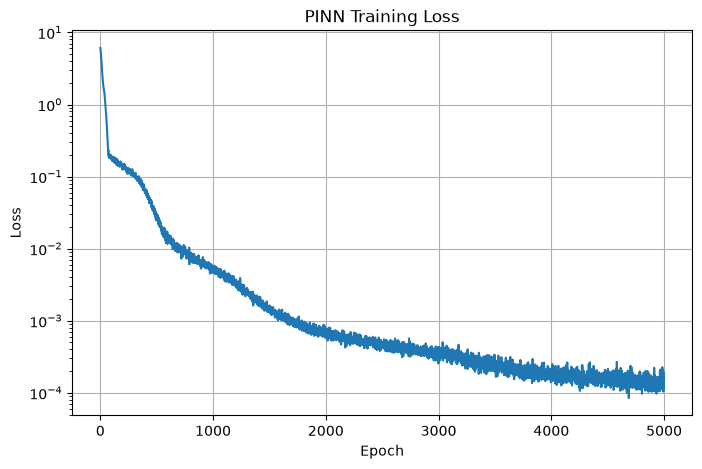

In [52]:
# Visualizing the training loss history.

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PINN Training Loss")
plt.grid(True)
plt.show()

In [53]:
# Create evaluation grid
S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PINN on the full grid
model.eval()
with torch.no_grad():
    V_pred = model(S_flat, tau_flat)

V_surface = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()

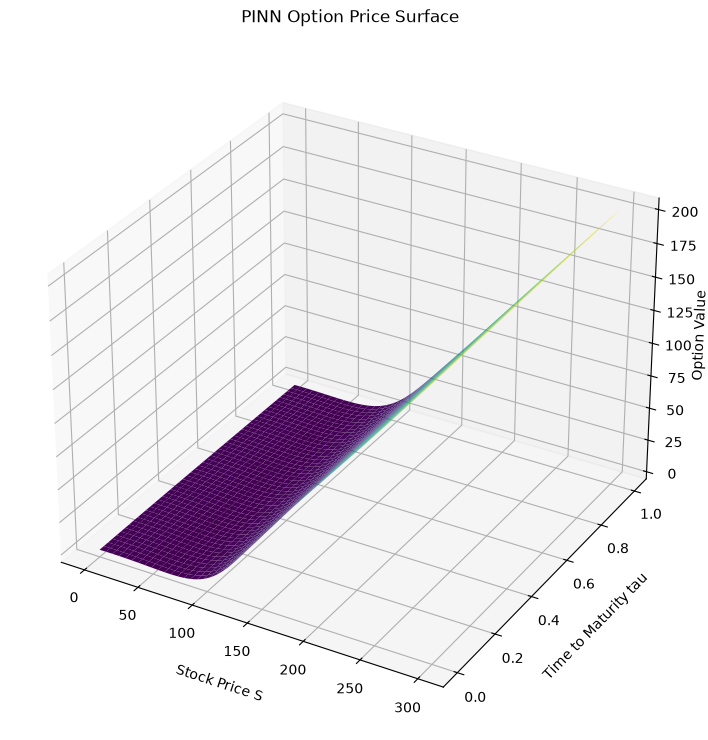

In [54]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(S_grid_np, tau_grid_np, V_surface, cmap="viridis")

ax.set_title("PINN Option Price Surface", pad=20)
ax.set_xlabel("Stock Price S", labelpad=10)
ax.set_ylabel("Time to Maturity tau", labelpad=10)
ax.set_zlabel("Option Value", labelpad=0)

fig.subplots_adjust(left=0.02, right=0.78, top=0.9, bottom=0.05)

plt.show()

In [55]:
# Then apply this function to the same grid of stock prices and times to maturity used for the PINN evaluation, and compute the analytical option prices.

V_exact_surface = black_scholes_call_grid(S_grid_np,tau_grid_np,K,r,sigma)

# Checking that the shapes of the PINN predictions and the analytical solution match, which is important for comparison and visualization.
print(V_surface.shape)
print(V_exact_surface.shape)

abs_error_surface = np.abs(V_surface - V_exact_surface)

(100, 50)
(100, 50)


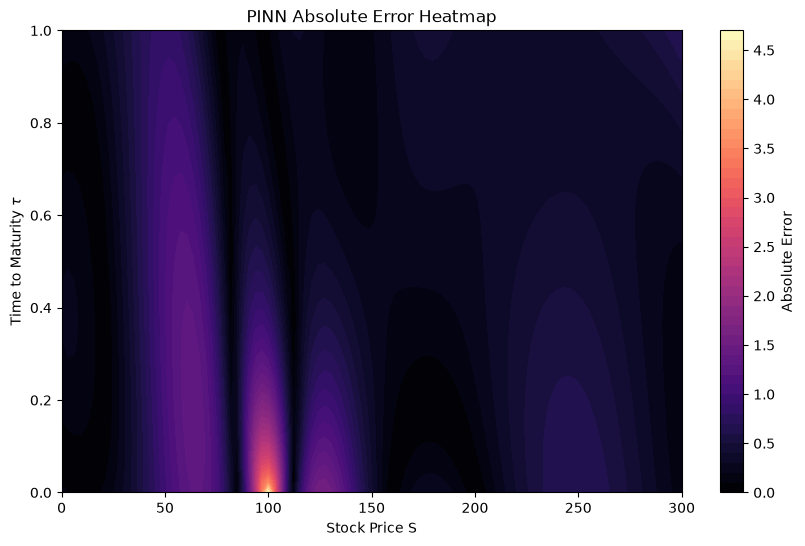

In [56]:
# Now, plot the absolute error heatmap between the PINN predictions and the analytical solution.
# Plotting a heatmap as it provides a clear visual representation of the error distribution across the grid of stock prices and times to maturity.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("PINN Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [57]:
# Plotting some key metrics for a more quantitative assessment of the PINN's performance against the analytical solution.

metrics = error_summary(V_surface, V_exact_surface)

metrics_table = pd.DataFrame({
    "Metric": metrics.keys(),
    "Value": metrics.values()
})

metrics_table

,Metric,Value
0,MSE,0.315081
1,RMSE,0.561320
2,MAE,0.429279
3,Max Abs Error,4.663443
4,Relative L2 Error,0.005808


The maximum absolute error occurs near the strike price $K=100$ and $\tau = 0$. An EU call payoff has a kink at this point which the PINN struggles to deal with given it uses smooth $\tanh()$ activation functions. Away from this point the error is much smaller.

## Tuning PINN

Here I will do some basic tuning to see if I can improve performance. 

* First I wll tune the architecture by increasing the number of neurons (i.e using a wider network).
* Then I will add a learning rate scheduler.
* Then I will increase the weight of the initial condition loss in my loss function, since this is the point where the max loss is achieved.

In [58]:
# Tuned PINN: wider network.

model_wide = BlackScholesPINN(
    layers=[2, 64, 64, 64, 1],
    S_max=S_max,
    T=T,
    price_scale=K
)

optimizer_wide = torch.optim.Adam(model_wide.parameters(), lr=1e-3)

loss_history_wide = []

epochs = 5000

N_f = 500
N_ic = 200
N_bc = 200


def train_step_wide():
    training_data = generate_training_points(
        N_f=N_f,
        N_ic=N_ic,
        N_bc=N_bc,
        S_max=S_max,
        T=T,
        K=K,
        r=r
    )

    optimizer_wide.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = black_scholes_pde_loss(
        model_wide,
        training_data,
        r=r,
        sigma=sigma,
        K=K
    )

    total_loss.backward()
    optimizer_wide.step()

    return (
        total_loss.detach().item(),
        loss_pde.detach().item(),
        loss_ic.detach().item(),
        loss_lb.detach().item(),
        loss_ub.detach().item()
    )


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step_wide()

    loss_history_wide.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}"
        )

Epoch 0: Total=4.290814e+00, PDE=5.663482e-03, IC=6.631142e-01, LB=1.948141e-02, UB=3.602555e+00
Epoch 500: Total=6.103128e-03, PDE=1.272321e-03, IC=4.310846e-03, LB=2.261456e-04, UB=2.938164e-04
Epoch 1000: Total=1.244574e-03, PDE=2.108633e-04, IC=9.021147e-04, LB=3.288509e-05, UB=9.871120e-05
Epoch 1500: Total=6.045378e-04, PDE=1.021519e-04, IC=4.178944e-04, LB=3.973435e-05, UB=4.475718e-05
Epoch 2000: Total=5.453615e-04, PDE=1.010358e-04, IC=4.136948e-04, LB=2.374783e-05, UB=6.883102e-06
Epoch 2500: Total=6.080322e-04, PDE=1.089666e-04, IC=4.721053e-04, LB=2.215146e-05, UB=4.808878e-06
Epoch 3000: Total=4.595490e-04, PDE=9.998342e-05, IC=3.418016e-04, LB=1.045121e-05, UB=7.312761e-06
Epoch 3500: Total=5.703405e-04, PDE=1.077264e-04, IC=4.072599e-04, LB=2.901614e-05, UB=2.633817e-05
Epoch 4000: Total=6.260073e-04, PDE=1.101580e-04, IC=3.320568e-04, LB=3.772538e-05, UB=1.460671e-04
Epoch 4500: Total=5.408613e-04, PDE=9.263383e-05, IC=2.437054e-04, LB=5.776066e-05, UB=1.467614e-04


In [47]:
# Create evaluation grid for tuned model.

S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PINN on the full grid
model_wide.eval()
with torch.no_grad():
    V_pred = model_wide(S_flat, tau_flat)

V_surface_modified = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()

modified_abs_error_surface = np.abs(V_surface_modified - V_exact_surface)


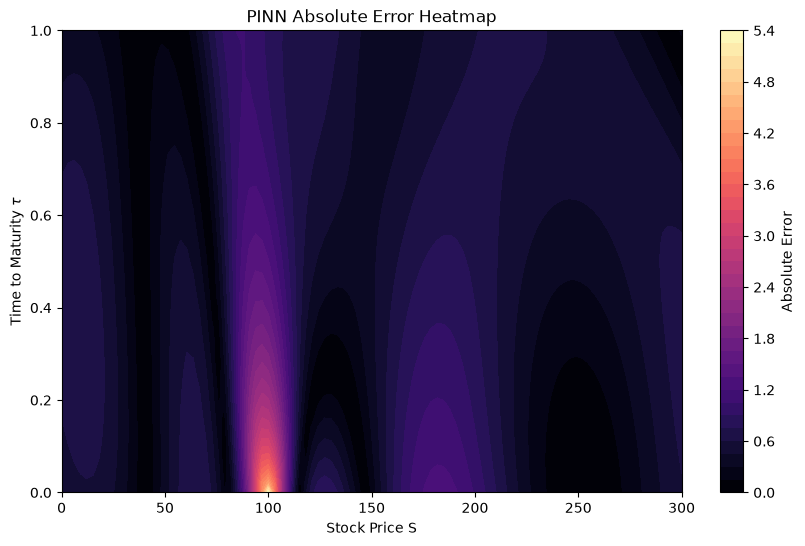

In [48]:
# Generating an error heatmap for the tuned model to visualize the absolute error between the PINN predictions and the analytical solution.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, modified_abs_error_surface, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("PINN Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [49]:
# Plotting some key metrics for a more quantitative assessment of the tuned PINN's performance against the analytical solution.

metrics_wide = error_summary(V_surface, V_exact_surface)

metrics_wide_table = pd.DataFrame({
    "Metric": metrics_wide.keys(),
    "Value": metrics_wide.values()
})

metrics_wide_table

,Metric,Value
0,MSE,0.250624
1,RMSE,0.500623
2,MAE,0.363268
3,Max Abs Error,4.505993
4,Relative L2 Error,0.005180


Clearly the performance has increased by using a wider network. Now I will add a learning rate scheduler to gradually reduce the learning rate as training goes on. This helps to make fine adjustments later on.



In [50]:
# Tuned PINN: wider network with learning rate scheduler.

model_wide_scheduler = BlackScholesPINN(
    layers=[2, 64, 64, 64, 1],
    S_max=S_max,
    T=T,
    price_scale=K
)

optimizer_wide_scheduler = torch.optim.Adam(
    model_wide_scheduler.parameters(),
    lr=1e-3
)

scheduler_wide = torch.optim.lr_scheduler.StepLR(
    optimizer_wide_scheduler,
    step_size=2000,
    gamma=0.5
)

loss_history_wide_scheduler = []

epochs = 5000

N_f = 500
N_ic = 200
N_bc = 200


def train_step_wide_scheduler():
    training_data = generate_training_points(
        N_f=N_f,
        N_ic=N_ic,
        N_bc=N_bc,
        S_max=S_max,
        T=T,
        K=K,
        r=r
    )

    optimizer_wide_scheduler.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = black_scholes_pde_loss(
        model_wide_scheduler,
        training_data,
        r=r,
        sigma=sigma,
        K=K
    )

    total_loss.backward()
    optimizer_wide_scheduler.step()

    return (
        total_loss.detach().item(),
        loss_pde.detach().item(),
        loss_ic.detach().item(),
        loss_lb.detach().item(),
        loss_ub.detach().item()
    )


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step_wide_scheduler()

    scheduler_wide.step()

    loss_history_wide_scheduler.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        current_lr = optimizer_wide_scheduler.param_groups[0]["lr"]

        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}, "
            f"LR={current_lr:.2e}"
        )

Epoch 0: Total=5.467763e+00, PDE=2.307883e-04, IC=9.969002e-01, LB=1.089952e-02, UB=4.459733e+00, LR=1.00e-03
Epoch 500: Total=8.748213e-03, PDE=1.463805e-03, IC=6.165257e-03, LB=7.410347e-04, UB=3.781157e-04, LR=1.00e-03
Epoch 1000: Total=1.929600e-03, PDE=5.018480e-04, IC=1.278661e-03, LB=3.727964e-05, UB=1.118109e-04, LR=1.00e-03
Epoch 1500: Total=9.064821e-04, PDE=2.519033e-04, IC=5.950353e-04, LB=3.203072e-05, UB=2.751279e-05, LR=1.00e-03
Epoch 2000: Total=8.272527e-04, PDE=1.707301e-04, IC=6.159834e-04, LB=1.523326e-05, UB=2.530597e-05, LR=5.00e-04
Epoch 2500: Total=6.484581e-04, PDE=1.554714e-04, IC=4.555532e-04, LB=3.192297e-05, UB=5.510511e-06, LR=5.00e-04
Epoch 3000: Total=7.167257e-04, PDE=1.371828e-04, IC=5.231297e-04, LB=3.115265e-05, UB=2.526057e-05, LR=5.00e-04
Epoch 3500: Total=5.814662e-04, PDE=1.167307e-04, IC=4.344834e-04, LB=1.939808e-05, UB=1.085402e-05, LR=5.00e-04
Epoch 4000: Total=4.073631e-04, PDE=1.178950e-04, IC=2.437955e-04, LB=3.834423e-05, UB=7.328420e-06,

In [59]:
# Create evaluation grid for model with learning rate scheduler.

S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PINN on the full grid
model_wide_scheduler.eval()
with torch.no_grad():
    V_pred = model_wide_scheduler(S_flat, tau_flat)

V_surface_scheduler = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()

abs_error_surface_scheduler = np.abs(V_surface_scheduler - V_exact_surface)


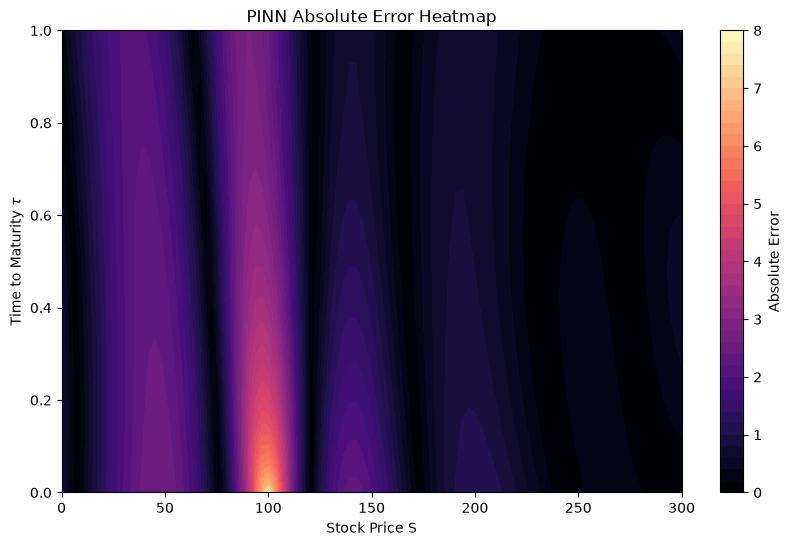

In [60]:
# Generating an error heatmap for the model with learning rate scheduler to visualize the absolute error between the PINN predictions and the analytical solution.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface_scheduler, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("PINN Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [61]:
# Plotting some key metrics for a more quantitative assessment of the PINN with learning rate scheduler's performance against the analytical solution.

metrics_wide_scheduler = error_summary(V_surface, V_exact_surface)

metrics_wide_scheduler_table = pd.DataFrame({
    "Metric": metrics_wide_scheduler.keys(),
    "Value": metrics_wide_scheduler.values()
})

metrics_wide_scheduler_table

,Metric,Value
0,MSE,0.315081
1,RMSE,0.561320
2,MAE,0.429279
3,Max Abs Error,4.663443
4,Relative L2 Error,0.005808


In [62]:
model_modified_loss = BlackScholesPINN(
    layers=[2, 64, 64, 64, 1],
    S_max=S_max,
    T=T,
    price_scale=K
)

optimizer_modified = torch.optim.Adam(model_modified_loss.parameters(), lr=1e-3)

scheduler_modified = torch.optim.lr_scheduler.StepLR(
    optimizer_modified,
    step_size=2000,
    gamma=0.5
)

loss_history_modified = []

epochs = 5000

N_f = 500
N_ic = 200
N_bc = 200


def train_step_modified():
    training_data = generate_training_points(
        N_f=N_f,
        N_ic=N_ic,
        N_bc=N_bc,
        S_max=S_max,
        T=T,
        K=K,
        r=r
    )

    optimizer_modified.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = black_scholes_pde_loss(
        model_modified_loss,
        training_data,
        r=r,
        sigma=sigma,
        K=K,
        weight_ic=5.0
    )

    total_loss.backward()
    optimizer_modified.step()

    values = (
        total_loss.detach().item(),
        loss_pde.detach().item(),
        loss_ic.detach().item(),
        loss_lb.detach().item(),
        loss_ub.detach().item()
    )

    return values


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step_modified()

    scheduler_modified.step()

    loss_history_modified.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        current_lr = optimizer_modified.param_groups[0]["lr"]

        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}, "
            f"LR={current_lr:.2e}"
        )

Epoch 0: Total=7.651179e+00, PDE=5.286835e-04, IC=8.135463e-01, LB=1.125663e-03, UB=3.581794e+00, LR=1.00e-03
Epoch 500: Total=1.252426e-02, PDE=2.111709e-03, IC=1.787125e-03, LB=1.033661e-04, UB=1.373561e-03, LR=1.00e-03
Epoch 1000: Total=1.963174e-03, PDE=4.551801e-04, IC=2.737185e-04, LB=6.709046e-05, UB=7.231112e-05, LR=1.00e-03
Epoch 1500: Total=7.269158e-04, PDE=2.527844e-04, IC=8.424677e-05, LB=4.101444e-05, UB=1.188306e-05, LR=1.00e-03
Epoch 2000: Total=1.125047e-03, PDE=1.680777e-04, IC=1.610903e-04, LB=6.280091e-05, UB=8.871685e-05, LR=5.00e-04
Epoch 2500: Total=3.507496e-04, PDE=1.436260e-04, IC=3.734597e-05, LB=9.457694e-06, UB=1.093598e-05, LR=5.00e-04
Epoch 3000: Total=3.462835e-04, PDE=1.506032e-04, IC=3.570187e-05, LB=4.317292e-06, UB=1.285371e-05, LR=5.00e-04
Epoch 3500: Total=4.005146e-04, PDE=1.452205e-04, IC=4.847986e-05, LB=4.901049e-06, UB=7.993830e-06, LR=5.00e-04
Epoch 4000: Total=3.486270e-04, PDE=1.225477e-04, IC=4.246048e-05, LB=7.715388e-06, UB=6.061492e-06,

In [63]:
# Create evaluation grid for model with modified loss function.

S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate PINN on the full grid
model_modified_loss.eval()
with torch.no_grad():
    V_pred = model_modified_loss(S_flat, tau_flat)

V_surface_modified_loss = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()

abs_error_surface_modified_loss = np.abs(V_surface_modified_loss - V_exact_surface)


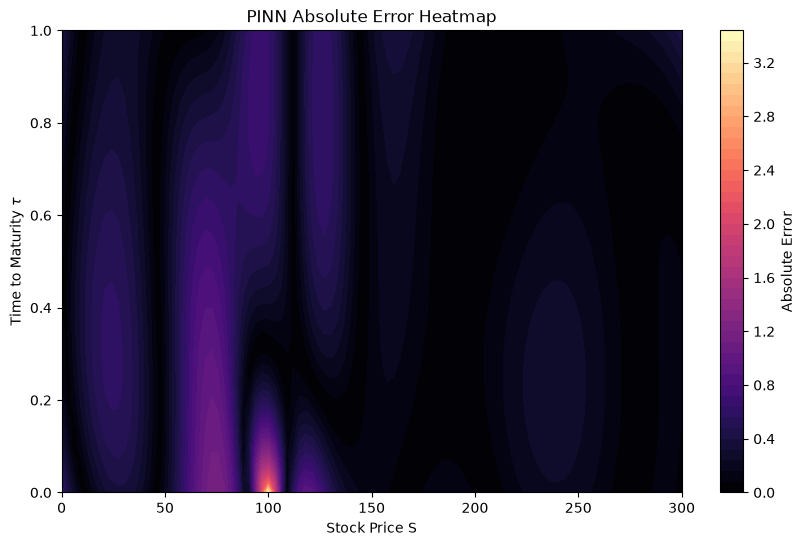

In [64]:
# Generating an error heatmap for the model with modified loss function to visualize the absolute error between the PINN predictions and the analytical solution.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface_modified_loss, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("PINN Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [65]:
# Plotting some key metrics for a more quantitative assessment of the PINN with modified loss function's performance against the analytical solution.

metrics_modified_loss = error_summary(V_surface, V_exact_surface)

metrics_modified_loss_table = pd.DataFrame({
    "Metric": metrics_modified_loss.keys(),
    "Value": metrics_modified_loss.values()
})

metrics_modified_loss_table

,Metric,Value
0,MSE,0.315081
1,RMSE,0.561320
2,MAE,0.429279
3,Max Abs Error,4.663443
4,Relative L2 Error,0.005808


In [66]:
# Generate a comparison table for the different PINN models.

from src.evaluation import compute_metric_row

comparison_rows = [
    compute_metric_row(
        model_name="Baseline PINN",
        model=model,
        architecture="[2, 32, 32, 32, 1]",
        scheduler="No",
        loss_type="Standard",
        S_grid=S_grid,
        tau_grid=tau_grid,
        K=K,
        r=r,
        sigma=sigma
    ),
    compute_metric_row(
        model_name="Wider PINN",
        model=model_wide,
        architecture="[2, 64, 64, 64, 1]",
        scheduler="No",
        loss_type="Standard",
        S_grid=S_grid,
        tau_grid=tau_grid,
        K=K,
        r=r,
        sigma=sigma
    ),
    compute_metric_row(
        model_name="Wider PINN + LR Scheduler",
        model=model_wide_scheduler,
        architecture="[2, 64, 64, 64, 1]",
        scheduler="StepLR",
        loss_type="Standard",
        S_grid=S_grid,
        tau_grid=tau_grid,
        K=K,
        r=r,
        sigma=sigma
    ),
    compute_metric_row(
        model_name="Wider PINN + Modified Loss",
        model=model_modified_loss,
        architecture="[2, 64, 64, 64, 1]",
        scheduler="StepLR",
        loss_type="Weighted IC",
        S_grid=S_grid,
        tau_grid=tau_grid,
        K=K,
        r=r,
        sigma=sigma
    )
]

comparison_table = pd.DataFrame(comparison_rows)

comparison_table

,Model,Architecture,Scheduler,Loss,MSE,RMSE,MAE,Max Abs Error,Relative L2 Error
0,Baseline PINN,"[2, 32, 32, 32, 1]",No,Standard,0.315081,0.561320,0.429279,4.663443,0.005808
1,Wider PINN,"[2, 64, 64, 64, 1]",No,Standard,1.047256,1.023355,0.860845,5.978008,0.010589
2,Wider PINN + LR Scheduler,"[2, 64, 64, 64, 1]",StepLR,Standard,1.963900,1.401392,0.992939,7.813058,0.014500
3,Wider PINN + Modified Loss,"[2, 64, 64, 64, 1]",StepLR,Weighted IC,0.117403,0.342642,0.243162,3.392542,0.003545


In [68]:
# Defining a function that counts the number of trainable parameters in a given model architecture.
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

count_parameters(model_modified_loss)

8577

The Wider PINN with learning rate scheduler and modified loss performed best on all metrics in this run. So from this point on I will use this network in the comparison with cPIKANs.